# Análise de praticantes de academia

Este notebook investiga associações entre intensidade, duração, experiência e gasto calórico em 973 registros do Gym Members Exercise Dataset. As análises são observacionais: descrevem padrões da base e não demonstram causalidade.


## Perguntas e estratégia analítica

- **H1.** A zona de intensidade ajuda a prever o gasto calórico por hora, junto às demais características disponíveis?
- **H2.** Sessões mais longas estão associadas a maior gasto calórico total?
- **H3.** O gasto calórico por hora difere entre níveis de experiência?

A EDA é usada para contextualizar os testes. Em H1, o modelo é validado com seleção de hiperparâmetros apenas no treino, validação cruzada e uma amostra de teste separada. Em H2 e H3, os resultados são acompanhados de diagnósticos e medidas de efeito.


## Dependências e reprodutibilidade

São utilizados pandas, numpy, matplotlib, seaborn, scipy, scikit-learn e xgboost. O random_state é fixado para tornar a divisão dos dados e a busca de hiperparâmetros reproduzíveis.


In [ ]:
# Se necessário, instale as bibliotecas:
# %pip install pandas numpy matplotlib seaborn scipy scikit-learn xgboost

import importlib
import itertools
import re
import unicodedata
import warnings
from pathlib import Path

required_packages = ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "sklearn", "xgboost"]
missing_packages = [pkg for pkg in required_packages if importlib.util.find_spec(pkg) is None]
if missing_packages:
    raise ImportError("Bibliotecas ausentes: " + ", ".join(missing_packages))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import xgboost as xgb
from xgboost import XGBRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate, train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")


## 1. Carregamento dos dados

Mantenha gym.csv no mesmo diretório deste notebook. O caminho efetivamente usado é exibido abaixo para facilitar a conferência.


In [ ]:
candidate_paths = [Path("gym.csv"), Path.cwd() / "gym.csv"]
DATA_PATH = next((path for path in candidate_paths if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Arquivo gym.csv não encontrado no diretório do notebook.")

raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy()
print(f"Arquivo carregado: {DATA_PATH}")
print(f"Dimensão inicial: {df.shape[0]} linhas e {df.shape[1]} colunas")
display(df.head())


Arquivo carregado: gym.csv
Dimensão inicial: 973 linhas e 15 colunas


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.300,1.710,180,157,60,1.690,"1,313.000",Yoga,12.600,3.500,4,3,30.200
1,46,Female,74.900,1.530,179,151,66,1.300,883.000,HIIT,33.900,2.100,4,2,32.000
2,32,Female,68.100,1.660,167,122,54,1.110,677.000,Cardio,33.400,2.300,4,2,24.710
3,25,Male,53.200,1.700,190,164,56,0.590,532.000,Strength,28.800,2.100,3,1,18.410
4,38,Male,46.100,1.790,188,158,68,0.640,556.000,Strength,29.200,2.800,3,1,14.390


### Origem e limite dos dados

A base é o Gym Members Exercise Dataset, disponibilizado no Kaggle. Ela não traz informações suficientes sobre amostragem, período de coleta ou representatividade. Portanto, as conclusões descrevem esta base e não devem ser generalizadas automaticamente para todos os praticantes de academia.


In [ ]:
print("Colunas originais:")
display(pd.DataFrame({"coluna": df.columns, "tipo": df.dtypes.astype(str).values}))

print("\nResumo estatístico das variáveis numéricas:")
display(df.describe().T)


Colunas originais:


,coluna,tipo
0,Age,int64
1,Gender,object
2,Weight (kg),float64
3,Height (m),float64
4,Max_BPM,int64
5,Avg_BPM,int64
6,Resting_BPM,int64
7,Session_Duration (hours),float64
8,Calories_Burned,float64
9,Workout_Type,object



Resumo estatístico das variáveis numéricas:


,count,mean,std,min,25%,50%,75%,max
Age,973.000,38.683,12.181,18.000,28.000,40.000,49.000,59.000
Weight (kg),973.000,73.855,21.208,40.000,58.100,70.000,86.000,129.900
Height (m),973.000,1.723,0.128,1.500,1.620,1.710,1.800,2.000
Max_BPM,973.000,179.884,11.526,160.000,170.000,180.000,190.000,199.000
Avg_BPM,973.000,143.767,14.345,120.000,131.000,143.000,156.000,169.000
Resting_BPM,973.000,62.223,7.327,50.000,56.000,62.000,68.000,74.000
Session_Duration (hours),973.000,1.256,0.343,0.500,1.040,1.260,1.460,2.000
Calories_Burned,973.000,905.422,272.642,303.000,720.000,893.000,"1,076.000","1,783.000"
Fat_Percentage,973.000,24.977,6.259,10.000,21.300,26.200,29.300,35.000
Water_Intake (liters),973.000,2.627,0.600,1.500,2.200,2.600,3.100,3.700


## 2. Padronização de nomes e inspeção inicial

Alguns datasets usam nomes com unidades entre parênteses, como Session_Duration (hours). Para manter consistência com as hipóteses, as colunas são padronizadas para nomes analíticos estáveis. Essa etapa não altera os valores, apenas os nomes das variáveis.


In [ ]:
rename_map = {
    "Session_Duration (hours)": "Session_Duration",
    "Weight (kg)": "Weight_kg",
    "Height (m)": "Height_m",
    "Water_Intake (liters)": "Water_Intake_liters",
    "Workout_Frequency (days/week)": "Workout_Frequency_days_per_week",
}

df = df.rename(columns={old: new for old, new in rename_map.items() if old in df.columns})

required_columns = ["Avg_BPM", "Max_BPM", "Calories_Burned", "Session_Duration", "Experience_Level"]
missing_required = [col for col in required_columns if col not in df.columns]

if missing_required:
    raise ValueError(
        "Colunas obrigatórias ausentes após padronização: "
        + ", ".join(missing_required)
        + ". Verifique os nomes das colunas do CSV."
    )

print("Colunas após padronização:")
display(pd.DataFrame({"coluna": df.columns, "tipo": df.dtypes.astype(str).values}))


Colunas após padronização:


,coluna,tipo
0,Age,int64
1,Gender,object
2,Weight_kg,float64
3,Height_m,float64
4,Max_BPM,int64
5,Avg_BPM,int64
6,Resting_BPM,int64
7,Session_Duration,float64
8,Calories_Burned,float64
9,Workout_Type,object


## 3. Limpeza dos dados

A limpeza faz a remoção de duplicatas, conversão de variáveis numéricas, tratamento de valores ausentes e verificação de valores incompatíveis com os cálculos do estudo. Em especial, Max_BPM, Avg_BPM, Session_Duration e Calories_Burned precisam ser numéricas e positivas para as variáveis derivadas.


In [ ]:
duplicate_count = df.duplicated().sum()
print(f"Registros duplicados identificados: {duplicate_count}")

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Dimensão após remoção de duplicatas: {df.shape}")

missing_table = (
    df.isna().sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_pct=lambda x: 100 * x["missing_count"] / len(df))
    .sort_values("missing_count", ascending=False)
)
display(missing_table)


Registros duplicados identificados: 0


,missing_count,missing_pct
Age,0,0.000
Gender,0,0.000
Weight_kg,0,0.000
Height_m,0,0.000
Max_BPM,0,0.000
Avg_BPM,0,0.000
Resting_BPM,0,0.000
Session_Duration,0,0.000
Calories_Burned,0,0.000
Workout_Type,0,0.000


In [ ]:
numeric_candidates = [
    "Age", "Weight_kg", "Height_m", "Max_BPM", "Avg_BPM", "Resting_BPM",
    "Session_Duration", "Calories_Burned", "Fat_Percentage",
    "Water_Intake_liters", "Workout_Frequency_days_per_week", "Experience_Level", "BMI"
]

for col in [c for c in numeric_candidates if c in df.columns]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Tratamento conservador de ausentes:
# - numéricas: mediana, por ser robusta a outliers;
# - categóricas: categoria explícita "Não informado".
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [col for col in df.columns if col not in numeric_cols]

for col in numeric_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna("Não informado")

invalid_mask = (
    (df["Max_BPM"] <= 0)
    | (df["Avg_BPM"] <= 0)
    | (df["Session_Duration"] <= 0)
    | (df["Calories_Burned"] < 0)
)

invalid_count = int(invalid_mask.sum())
if invalid_count > 0:
    print(f"Registros removidos por valores incompatíveis com os cálculos: {invalid_count}")
    df = df.loc[~invalid_mask].reset_index(drop=True)

print(f"Dimensão após limpeza: {df.shape[0]} linhas e {df.shape[1]} colunas")
display(df.isna().sum().rename("ausentes após tratamento").to_frame())


Dimensão após limpeza: 973 linhas e 15 colunas


,ausentes após tratamento
Age,0
Gender,0
Weight_kg,0
Height_m,0
Max_BPM,0
Avg_BPM,0
Resting_BPM,0
Session_Duration,0
Calories_Burned,0
Workout_Type,0


## 4. Variáveis analíticas

A intensidade relativa é definida por Avg_BPM / Max_BPM e convertida em zonas. Calories_per_Hour = Calories_Burned / Session_Duration é a medida de gasto padronizada pela duração: ela é o desfecho de H1 e H3. Em H2, usa-se o gasto total porque a própria pergunta trata da duração da sessão.


In [ ]:
df["Intensity_Ratio"] = df["Avg_BPM"] / df["Max_BPM"]
df["Intensity_Zone"] = pd.cut(
    df["Intensity_Ratio"],
    bins=[-np.inf, 0.70, 0.85, np.inf],
    labels=["Moderada (<=70%)", "Vigorosa (70-85%)", "Máxima (>85%)"],
    ordered=True,
)
df["Calories_per_Hour"] = df["Calories_Burned"] / df["Session_Duration"]

display(
    df[["Avg_BPM", "Max_BPM", "Intensity_Ratio", "Intensity_Zone", "Calories_Burned", "Session_Duration", "Calories_per_Hour"]]
    .head()
)

print("Distribuição das zonas de intensidade:")
display(df["Intensity_Zone"].value_counts(dropna=False).rename("frequência").to_frame())


,Avg_BPM,Max_BPM,Intensity_Ratio,Intensity_Zone,Calories_Burned,Session_Duration,Calories_per_Hour
0,157,180,0.872,Máxima (>85%),"1,313.000",1.690,776.923
1,151,179,0.844,Vigorosa (70-85%),883.000,1.300,679.231
2,122,167,0.731,Vigorosa (70-85%),677.000,1.110,609.910
3,164,190,0.863,Máxima (>85%),532.000,0.590,901.695
4,158,188,0.840,Vigorosa (70-85%),556.000,0.640,868.750


Distribuição das zonas de intensidade:


,frequência
Intensity_Zone,
Vigorosa (70-85%),511
Máxima (>85%),304
Moderada (<=70%),158


## 5. Codificação de variáveis categóricas

Para o XGBoost, variáveis categóricas são convertidas por one-hot encoding. O Experience_Level é preservado como variável ordinal quando seus valores são numéricos, pois representa uma progressão de experiência. Essa codificação é feita apenas após a separação conceitual entre variáveis explicativas e alvo, evitando incluir variáveis derivadas do desfecho.

**Normalização.** O XGBoost não exige normalização ou padronização das variáveis numéricas, pois árvores de decisão particionam os dados por limiares. Transformações de escala não mudam a ordem dos valores e, portanto, não são necessárias para o algoritmo.


In [ ]:
encoded_preview = pd.get_dummies(
    df[["Intensity_Zone"] + [c for c in ["Gender", "Workout_Type"] if c in df.columns]].astype("category"),
    drop_first=False,
    dtype=int,
)

print("Exemplo de codificação one-hot que será usada na modelagem:")
display(encoded_preview.head())


Exemplo de codificação one-hot que será usada na modelagem:


,Intensity_Zone_Moderada (<=70%),Intensity_Zone_Vigorosa (70-85%),Intensity_Zone_Máxima (>85%),Gender_Female,Gender_Male,Workout_Type_Cardio,Workout_Type_HIIT,Workout_Type_Strength,Workout_Type_Yoga
0,0,0,1,0,1,0,0,0,1
1,0,1,0,1,0,0,1,0,0
2,0,1,0,1,0,1,0,0,0
3,0,0,1,0,1,0,0,1,0
4,0,1,0,0,1,0,0,1,0


## 6. Análise exploratória: histogramas

Os histogramas permitem avaliar forma, assimetria e concentração das variáveis numéricas. Essa etapa orienta a escolha dos testes estatísticos em H2 e H3, especialmente quanto à normalidade aproximada.


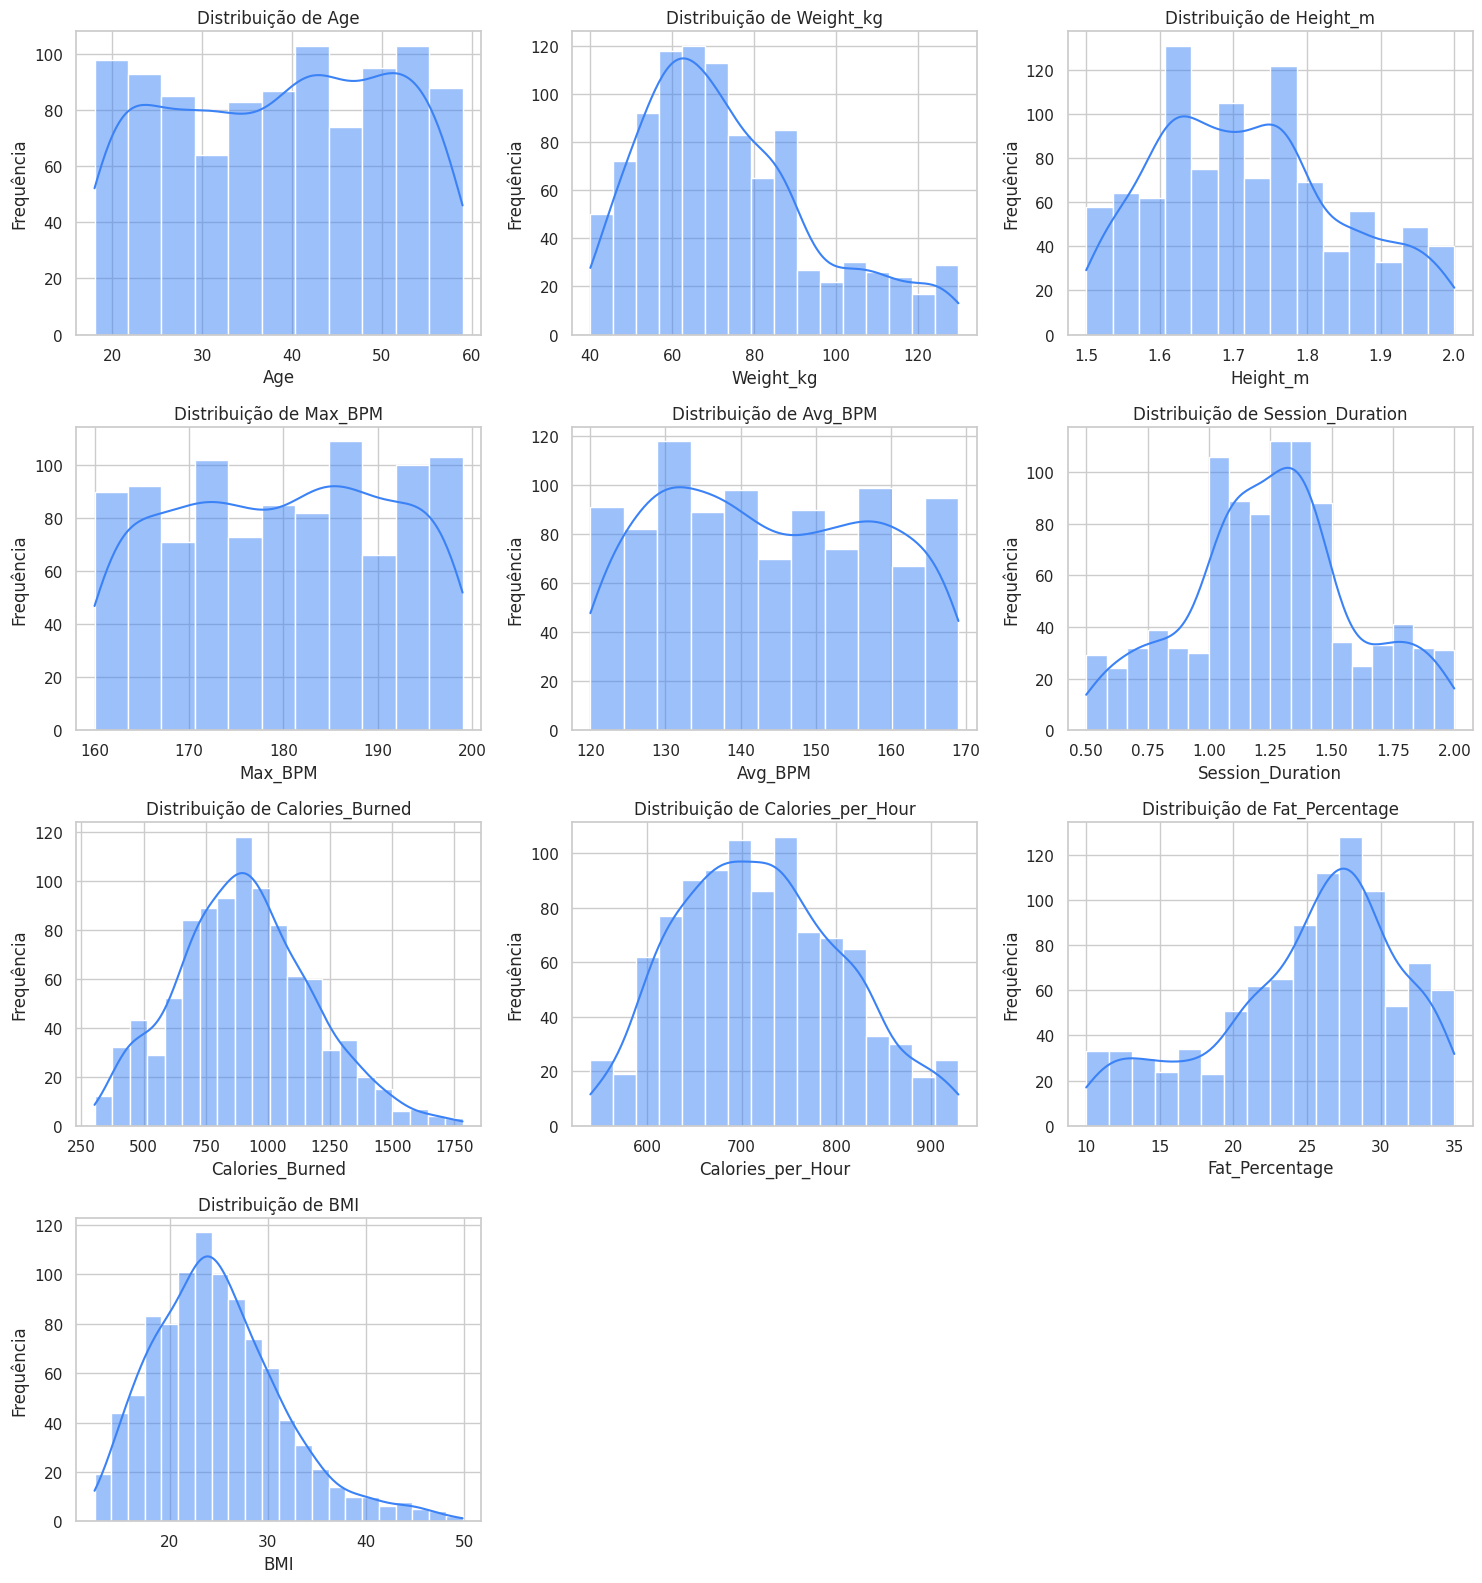

Interpretação:
Variáveis com maior assimetria absoluta exigem cautela na aplicação de testes paramétricos. Abaixo estão as assimetrias observadas, ordenadas por magnitude.


,assimetria
Weight_kg,0.772
BMI,0.764
Fat_Percentage,-0.635
Height_m,0.339
Calories_Burned,0.278
Calories_per_Hour,0.246
Avg_BPM,0.086
Age,-0.078
Max_BPM,-0.038
Session_Duration,0.026


In [ ]:
plot_numeric = [col for col in [
    "Age", "Weight_kg", "Height_m", "Max_BPM", "Avg_BPM", "Session_Duration",
    "Calories_Burned", "Calories_per_Hour", "Fat_Percentage", "BMI"
] if col in df.columns]

n_cols = 3
n_rows = int(np.ceil(len(plot_numeric) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, plot_numeric):
    sns.histplot(df[col], kde=True, ax=ax, color="#3b82f6")
    ax.set_title(f"Distribuição de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequência")

for ax in axes[len(plot_numeric):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

skewness = df[plot_numeric].skew(numeric_only=True).sort_values(key=lambda s: s.abs(), ascending=False)
print("Interpretação:")
print(
    "Variáveis com maior assimetria absoluta exigem cautela na aplicação de testes paramétricos. "
    "Abaixo estão as assimetrias observadas, ordenadas por magnitude."
)
display(skewness.rename("assimetria").to_frame())


## 7. Análise exploratória: boxplots

Os boxplots sintetizam mediana, dispersão e possíveis outliers. No contexto deste estudo, eles ajudam a observar diferenças de Calories_per_Hour por zona de intensidade e por nível de experiência.


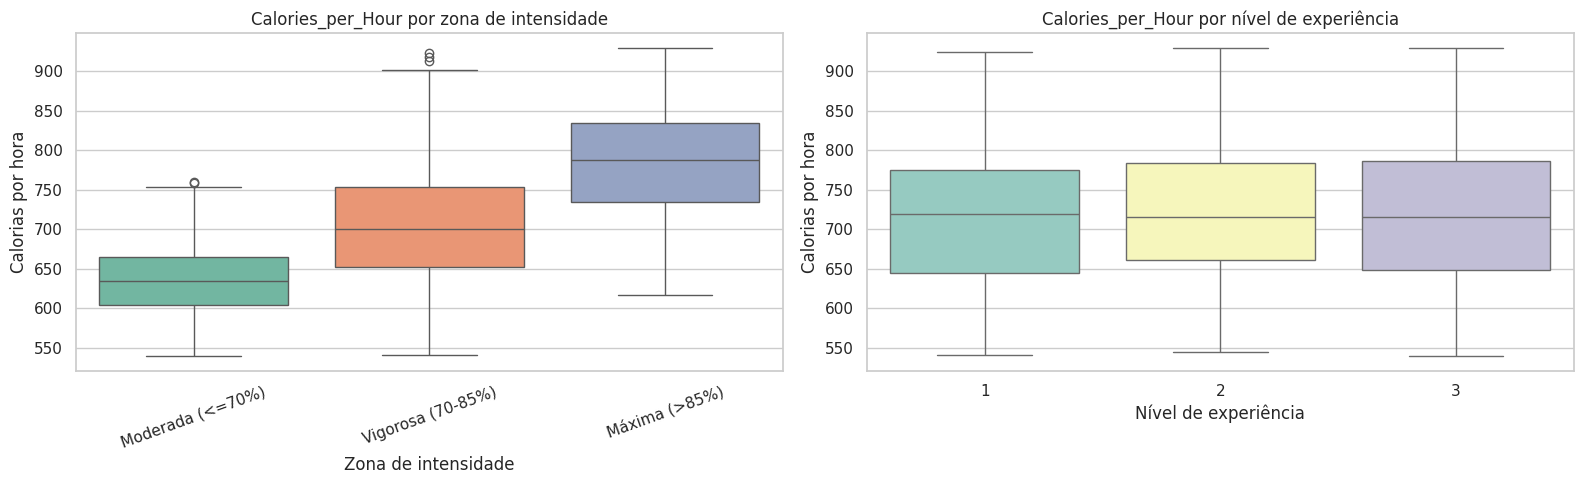

Interpretação:
As diferenças entre medianas e a presença de outliers indicam se o gasto por hora varia entre grupos e se a média pode ser influenciada por valores extremos.


,count,mean,median,std
Intensity_Zone,,,,
Moderada (<=70%),158,637.114,634.833,50.815
Vigorosa (70-85%),511,705.846,700.000,74.496
Máxima (>85%),304,788.219,788.417,70.551


,count,mean,median,std
Experience_Level,,,,
1,376,718.788,719.688,88.766
2,406,722.415,715.242,84.104
3,191,719.399,715.084,89.559


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=df, x="Intensity_Zone", y="Calories_per_Hour", ax=axes[0], palette="Set2")
axes[0].set_title("Calories_per_Hour por zona de intensidade")
axes[0].set_xlabel("Zona de intensidade")
axes[0].set_ylabel("Calorias por hora")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=df, x="Experience_Level", y="Calories_per_Hour", ax=axes[1], palette="Set3")
axes[1].set_title("Calories_per_Hour por nível de experiência")
axes[1].set_xlabel("Nível de experiência")
axes[1].set_ylabel("Calorias por hora")

plt.tight_layout()
plt.show()

intensity_summary = df.groupby("Intensity_Zone", observed=True)["Calories_per_Hour"].agg(["count", "mean", "median", "std"])
experience_summary = df.groupby("Experience_Level", observed=True)["Calories_per_Hour"].agg(["count", "mean", "median", "std"])

print("Interpretação:")
print(
    "As diferenças entre medianas e a presença de outliers indicam se o gasto por hora varia entre grupos "
    "e se a média pode ser influenciada por valores extremos."
)
display(intensity_summary)
display(experience_summary)


### Decisão sobre outliers

Os boxplots podem indicar observações extremas em Calories_per_Hour ou em outras variáveis numéricas. Neste estudo, optou-se por não remover outliers automaticamente quando os valores são fisiologicamente plausíveis. A justificativa é que praticantes com perfis extremos, maior condicionamento ou sessões incomuns podem ser parte legítima da população analisada.

A limpeza remove apenas valores incompatíveis com os cálculos, como duração menor ou igual a zero, frequência cardíaca não positiva ou calorias negativas. Para a modelagem, o XGBoost tende a ser mais robusto a outliers do que modelos lineares simples, pois usa divisões por árvores. Para os testes estatísticos, quando os pressupostos não são atendidos, o notebook seleciona alternativas não paramétricas, como Spearman e Kruskal-Wallis.


In [ ]:
outlier_rows = []
for col in plot_numeric:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_rows.append({
        "variável": col,
        "limite_inferior_IQR": lower,
        "limite_superior_IQR": upper,
        "outliers_IQR": count,
        "percentual": 100 * count / len(df)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values("outliers_IQR", ascending=False)
display(outlier_summary)

print("Decisão metodológica:")
print(
    "Os outliers foram documentados, mas mantidos quando não eram erros lógicos. "
    "Essa decisão preserva a variabilidade real dos praticantes e evita descartar perfis extremos legítimos."
)


,variável,limite_inferior_IQR,limite_superior_IQR,outliers_IQR,percentual
9,BMI,7.435,41.235,25,2.569
6,Calories_Burned,186.000,"1,610.000",10,1.028
1,Weight_kg,16.250,127.850,9,0.925
0,Age,-3.500,80.500,0,0.000
2,Height_m,1.350,2.070,0,0.000
3,Max_BPM,140.000,220.000,0,0.000
5,Session_Duration,0.410,2.090,0,0.000
4,Avg_BPM,93.500,193.500,0,0.000
7,Calories_per_Hour,465.972,971.528,0,0.000
8,Fat_Percentage,9.300,41.300,0,0.000


Decisão metodológica:
Os outliers foram documentados, mas mantidos quando não eram erros lógicos. Essa decisão preserva a variabilidade real dos praticantes e evita descartar perfis extremos legítimos.


## 8. Análise exploratória: gráficos de barras

Os gráficos de barras descrevem a composição da amostra e as médias de gasto calórico por grupos. Eles não substituem os testes estatísticos, mas ajudam a contextualizar a direção dos efeitos.


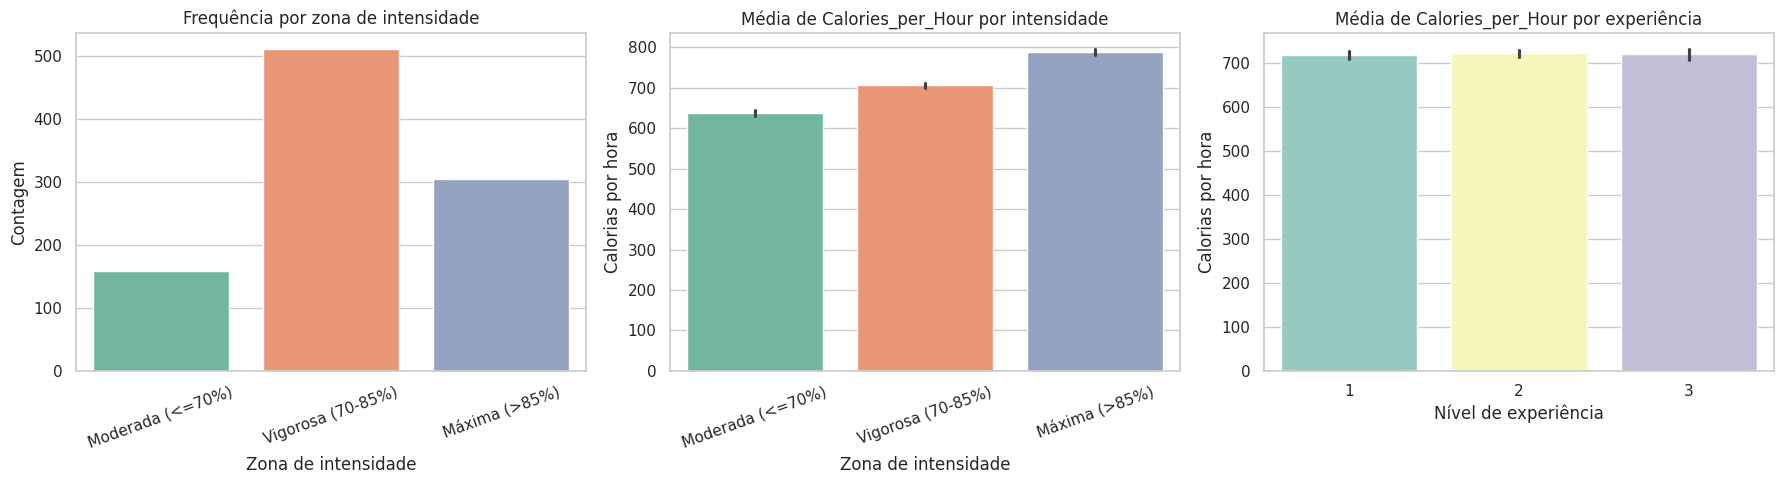

Interpretação:
Barras mais altas indicam maior gasto calórico médio por hora. Intervalos de confiança muito sobrepostos sugerem que a diferença visual deve ser confirmada por teste estatístico.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df, x="Intensity_Zone", ax=axes[0], palette="Set2")
axes[0].set_title("Frequência por zona de intensidade")
axes[0].set_xlabel("Zona de intensidade")
axes[0].set_ylabel("Contagem")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=df, x="Intensity_Zone", y="Calories_per_Hour", ax=axes[1], palette="Set2", ci=95)
axes[1].set_title("Média de Calories_per_Hour por intensidade")
axes[1].set_xlabel("Zona de intensidade")
axes[1].set_ylabel("Calorias por hora")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(data=df, x="Experience_Level", y="Calories_per_Hour", ax=axes[2], palette="Set3", ci=95)
axes[2].set_title("Média de Calories_per_Hour por experiência")
axes[2].set_xlabel("Nível de experiência")
axes[2].set_ylabel("Calorias por hora")

plt.tight_layout()
plt.show()

print("Interpretação:")
print(
    "Barras mais altas indicam maior gasto calórico médio por hora. "
    "Intervalos de confiança muito sobrepostos sugerem que a diferença visual deve ser confirmada por teste estatístico."
)


## 9. Análise exploratória: dispersão

O gráfico de dispersão entre Session_Duration e Calories_Burned é diretamente relacionado à H2. Uma tendência crescente sugere associação positiva entre duração da sessão e gasto calórico total.


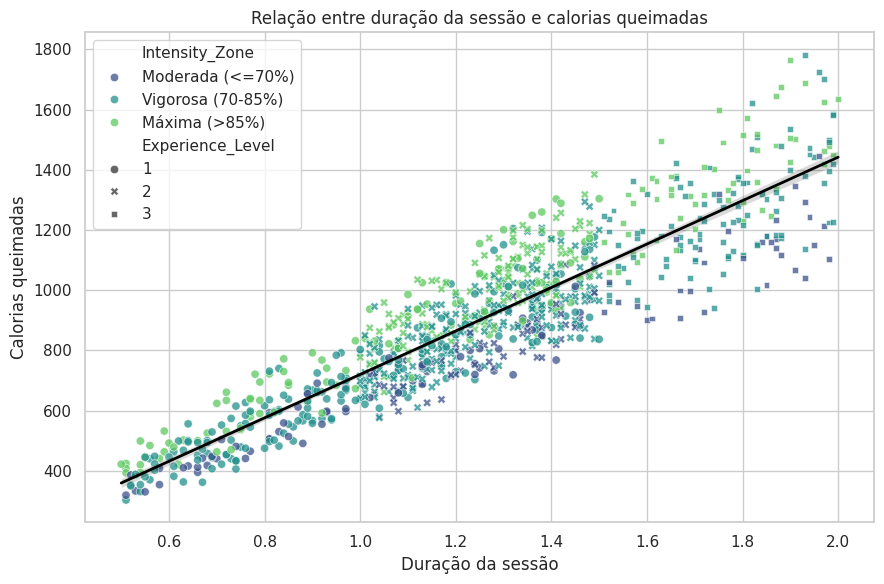

Interpretação:
A nuvem de pontos e a linha de tendência permitem avaliar visualmente a direção da associação. A confirmação formal é feita na H2 por Pearson ou Spearman.


In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Session_Duration",
    y="Calories_Burned",
    hue="Intensity_Zone",
    style="Experience_Level",
    palette="viridis",
    alpha=0.75,
)
sns.regplot(
    data=df,
    x="Session_Duration",
    y="Calories_Burned",
    scatter=False,
    color="black",
    line_kws={"linewidth": 2},
)
plt.title("Relação entre duração da sessão e calorias queimadas")
plt.xlabel("Duração da sessão")
plt.ylabel("Calorias queimadas")
plt.tight_layout()
plt.show()

print("Interpretação:")
print(
    "A nuvem de pontos e a linha de tendência permitem avaliar visualmente a direção da associação. "
    "A confirmação formal é feita na H2 por Pearson ou Spearman."
)


## 10. Análise exploratória: correlação

A matriz de correlação descreve associações lineares entre variáveis numéricas. Correlações próximas de 1 ou -1 indicam associação forte; correlações próximas de 0 indicam associação linear fraca.


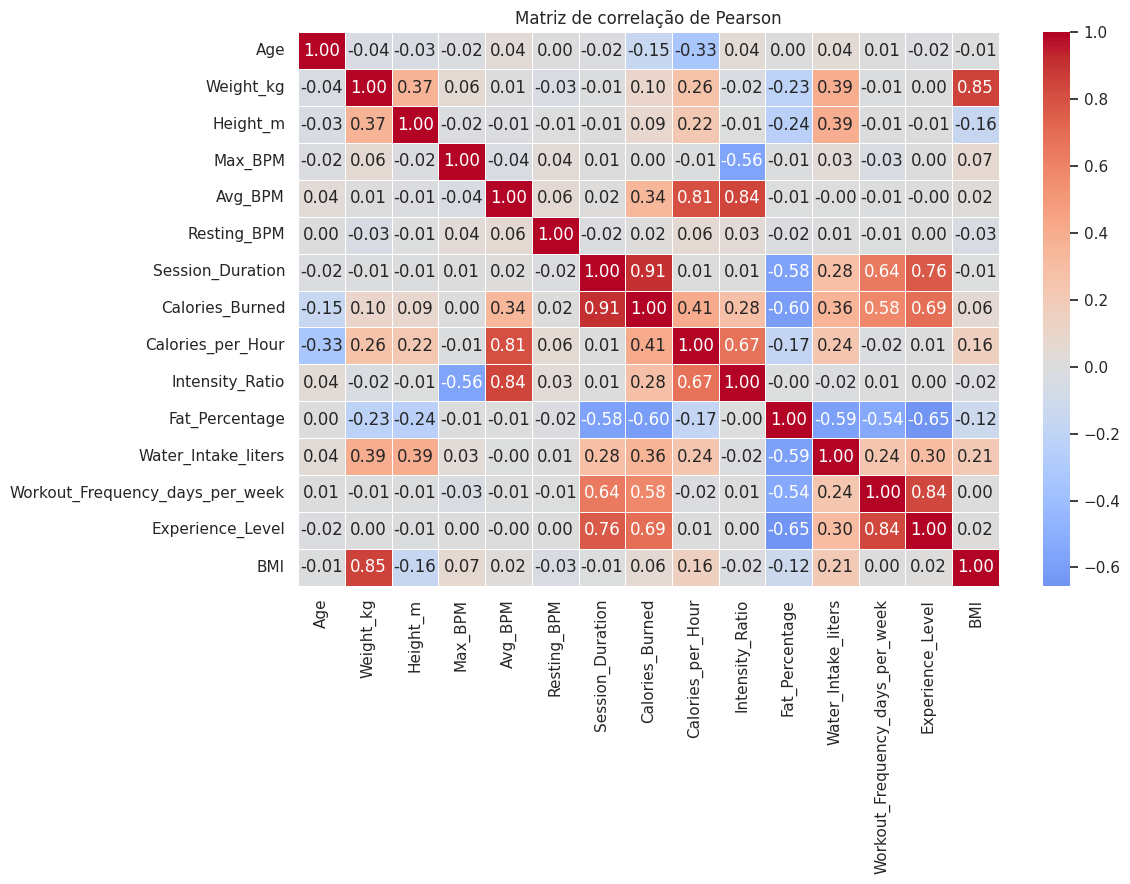

Interpretação:
A matriz ajuda a identificar variáveis potencialmente associadas ao gasto calórico. A relação específica entre duração e calorias é testada formalmente na H2.


In [ ]:
corr_cols = [col for col in [
    "Age", "Weight_kg", "Height_m", "Max_BPM", "Avg_BPM", "Resting_BPM",
    "Session_Duration", "Calories_Burned", "Calories_per_Hour", "Intensity_Ratio",
    "Fat_Percentage", "Water_Intake_liters", "Workout_Frequency_days_per_week",
    "Experience_Level", "BMI"
] if col in df.columns]

corr = df[corr_cols].corr(method="pearson")

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Matriz de correlação de Pearson")
plt.tight_layout()
plt.show()

print("Interpretação:")
print(
    "A matriz ajuda a identificar variáveis potencialmente associadas ao gasto calórico. "
    "A relação específica entre duração e calorias é testada formalmente na H2."
)


## 11. Hipóteses após a exploração

Os gráficos orientam a leitura, mas não substituem os testes nem permitem afirmações causais.

- **H1:** zona de intensidade e nível de experiência possuem informação preditiva para Calories_per_Hour.
- **H2:** Session_Duration e Calories_Burned apresentam associação positiva.
- **H3:** Calories_per_Hour difere entre os níveis de Experience_Level.


In [ ]:
insight_summary = {
    "Intensidade e gasto por hora": (
        df.groupby("Intensity_Zone", observed=True)["Calories_per_Hour"].mean()
        .sort_values(ascending=False)
        .to_dict()
    ),
    "Correlação duração-calorias": df[["Session_Duration", "Calories_Burned"]].corr(method="spearman").iloc[0, 1],
    "Média de calorias por experiência": (
        df.groupby("Experience_Level", observed=True)["Calories_Burned"].mean()
        .sort_index()
        .to_dict()
    ),
}

print("Resumo dos sinais exploratórios que motivaram as hipóteses:")
for item, value in insight_summary.items():
    print(f"- {item}: {value}")


Resumo dos sinais exploratórios que motivaram as hipóteses:
- Intensidade e gasto por hora: {'Máxima (>85%)': 788.21896325898, 'Vigorosa (70-85%)': 705.8460391178897, 'Moderada (<=70%)': 637.1139308561677}
- Correlação duração-calorias: 0.9034784709494303
- Média de calorias por experiência: {1: 726.375, 2: 901.9187192118227, 3: 1265.3403141361257}


## 12. H1: XGBoost para prever Calories_per_Hour

O objetivo é preditivo,. Calories_Burned e Session_Duration são removidas por formarem o alvo; Avg_BPM, Max_BPM e Intensity_Ratio também são removidas porque definem a zona de intensidade. Assim, a contribuição de Intensity_Zone pode ser interpretada sem duplicar suas variáveis de origem.


### Validação e escolha dos hiperparâmetros

Reserva-se 20% da base como teste final, estratificando pela zona de intensidade. No restante, uma busca aleatória limitada seleciona combinações plausíveis de profundidade, número de árvores, taxa de aprendizado, amostragem e regularização por validação cruzada de cinco dobras. A busca usa MAE como critério; depois, os parâmetros escolhidos são reavaliados por validação cruzada no treino e uma única vez no teste.

Esse procedimento reduz a dependência de um único particionamento. Ele ainda não substitui validação externa em uma nova amostra.


,Experience_Level,Intensity_Zone,count,mean,median,std
0,1,Moderada (<=70%),64,644.954,638.632,49.109
1,1,Vigorosa (70-85%),202,700.972,700.397,75.228
2,1,Máxima (>85%),110,794.461,796.734,75.568
3,2,Moderada (<=70%),61,637.430,639.000,48.396
4,2,Vigorosa (70-85%),209,706.204,698.000,71.293
5,2,Máxima (>85%),136,785.447,786.060,68.376
6,3,Moderada (<=70%),33,621.325,615.228,56.114
7,3,Vigorosa (70-85%),100,714.943,708.634,79.296
8,3,Máxima (>85%),58,782.880,781.917,65.904


Distribuição conjunta de Experience_Level e Intensity_Zone:


Intensity_Zone,Moderada (<=70%),Vigorosa (70-85%),Máxima (>85%),All
Experience_Level,,,,
1,64,202,110,376
2,61,209,136,406
3,33,100,58,191
All,158,511,304,973


Comentário sobre balanceamento: como o alvo é contínuo, não foi aplicado balanceamento de classes. O menor grupo experiência x intensidade possui 33 observações; grupos muito pequenos devem ser interpretados com cautela.


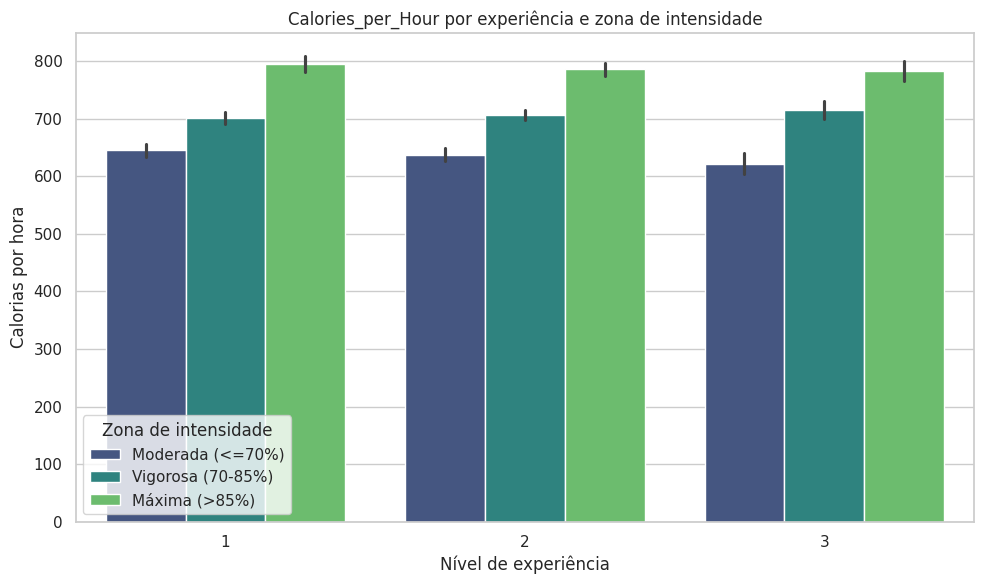

Interpretação descritiva:
No nível de experiência 1, a média da zona máxima foi maior que as demais zonas observadas.
No nível de experiência 2, a média da zona máxima foi maior que as demais zonas observadas.
No nível de experiência 3, a média da zona máxima foi maior que as demais zonas observadas.


In [ ]:
h1_summary = (
    df.groupby(["Experience_Level", "Intensity_Zone"], observed=True)["Calories_per_Hour"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
    .sort_values(["Experience_Level", "Intensity_Zone"])
)
display(h1_summary)

balance_summary = pd.crosstab(df["Experience_Level"], df["Intensity_Zone"], margins=True)
print("Distribuição conjunta de Experience_Level e Intensity_Zone:")
display(balance_summary)

min_group_size = (
    df.groupby(["Experience_Level", "Intensity_Zone"], observed=True)
    .size()
    .min()
)
print(
    " Como o alvo é contínuo, não foi aplicado balanceamento de classes. "
    f"O menor grupo experiência x intensidade possui {min_group_size} observações; "
    "grupos muito pequenos devem ser interpretados com cautela."
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=df,
    x="Experience_Level",
    y="Calories_per_Hour",
    hue="Intensity_Zone",
    palette="viridis",
    ci=95,
)
plt.title("Calories_per_Hour por experiência e zona de intensidade")
plt.xlabel("Nível de experiência")
plt.ylabel("Calorias por hora")
plt.legend(title="Zona de intensidade")
plt.tight_layout()
plt.show()

print("Interpretação descritiva:")
for exp_level, sub in h1_summary.groupby("Experience_Level"):
    means = sub.set_index("Intensity_Zone")["mean"]
    max_mean = means.get("Máxima (>85%)", np.nan)
    other_means = means.drop(labels=["Máxima (>85%)"], errors="ignore")
    if pd.notna(max_mean) and len(other_means) > 0:
        relation = "maior" if max_mean > other_means.max() else "não maior"
        print(
            f"No nível de experiência {exp_level}, a média da zona máxima foi {relation} "
            f"que as demais zonas observadas."
        )


In [ ]:
target = "Calories_per_Hour"
leakage_or_derived = {
    "Calories_Burned", "Session_Duration", "Avg_BPM", "Max_BPM", "Intensity_Ratio", target
}
candidate_features = [col for col in df.columns if col not in leakage_or_derived]

model_df = df[candidate_features + [target]].dropna().copy()
X_raw = model_df[candidate_features].copy()
y = model_df[target].astype(float).copy()

numeric_features = X_raw.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [col for col in X_raw.columns if col not in numeric_features]
for col in numeric_features:
    X_raw[col] = X_raw[col].fillna(X_raw[col].median())
for col in categorical_features:
    X_raw[col] = X_raw[col].astype("object").fillna("Não informado")

X = pd.get_dummies(X_raw, columns=categorical_features, drop_first=False, dtype=float)

def sanitize_feature_name(name):
    normalized = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode("ascii")
    normalized = re.sub(r"[^0-9a-zA-Z_]+", "_", normalized).strip("_")
    return normalized or "feature"

sanitized_columns = []
seen = {}
for col in X.columns:
    clean_col = sanitize_feature_name(col)
    count = seen.get(clean_col, 0)
    seen[clean_col] = count + 1
    sanitized_columns.append(clean_col if count == 0 else f"{clean_col}_{count}")

feature_name_map = pd.DataFrame({"original": X.columns, "sanitized": sanitized_columns})
X.columns = sanitized_columns

stratify_labels = X_raw["Intensity_Zone"]
if stratify_labels.value_counts().min() < 2:
    stratify_labels = None

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=stratify_labels
)

print(f"Observações no modelo: {len(X)}")
print(f"Treino: {len(X_train)} | Teste final: {len(X_test)}")
print(f"Features após one-hot encoding: {X.shape[1]}")
display(feature_name_map.head(20))


Observações no modelo: 973
Treino: 778 | Teste final: 195
Features após one-hot encoding: 18


,original,sanitized
0,Age,Age
1,Weight_kg,Weight_kg
2,Height_m,Height_m
3,Resting_BPM,Resting_BPM
4,Fat_Percentage,Fat_Percentage
5,Water_Intake_liters,Water_Intake_liters
6,Workout_Frequency_days_per_week,Workout_Frequency_days_per_week
7,Experience_Level,Experience_Level
8,BMI,BMI
9,Gender_Female,Gender_Female


,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree
selecionado no treino,0.850,1.000,400,5,4,0.020,0.850


MAE médio da busca (CV interna): 39.31


,Métrica,Média (CV de 5 dobras),Desvio-padrão
0,MAE,39.305,2.261
1,RMSE,49.393,2.462
2,R²,0.678,0.037


,Métrica,Teste final
0,MAE,36.697
1,RMSE,46.248
2,R²,0.695


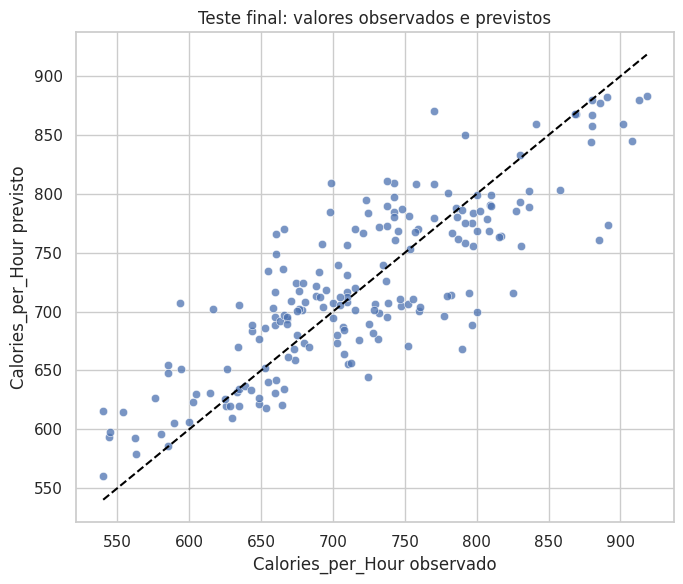

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

base_model = XGBRegressor(
    objective="reg:squarederror",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=1,
)

# Espaço de busca deliberadamente pequeno: a base tem menos de mil registros.
param_distributions = {
    "n_estimators": [200, 400, 600],
    "learning_rate": [0.02, 0.05, 0.08],
    "max_depth": [2, 3, 4],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.70, 0.85, 1.00],
    "colsample_bytree": [0.70, 0.85, 1.00],
    "reg_lambda": [1.0, 5.0, 10.0],
}

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=18,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
)
search.fit(X_train, y_train)
model = search.best_estimator_

best_params = pd.DataFrame([search.best_params_], index=["selecionado no treino"])
display(best_params)
print(f"MAE médio da busca (CV interna): {-search.best_score_:.2f}")

cv_scores = cross_validate(
    clone(model),
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2",
    },
)
cv_summary = pd.DataFrame({
    "Métrica": ["MAE", "RMSE", "R²"],
    "Média (CV de 5 dobras)": [
        -cv_scores["test_MAE"].mean(),
        -cv_scores["test_RMSE"].mean(),
        cv_scores["test_R2"].mean(),
    ],
    "Desvio-padrão": [
        cv_scores["test_MAE"].std(),
        cv_scores["test_RMSE"].std(),
        cv_scores["test_R2"].std(),
    ],
})
display(cv_summary)

y_pred = pd.Series(model.predict(X_test), index=y_test.index, name="previsto")
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)
metrics = pd.DataFrame({"Métrica": ["MAE", "RMSE", "R²"], "Teste final": [mae, rmse, r2]})
display(metrics)

plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.75)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limits, limits, color="black", linestyle="--")
plt.title("Teste final: valores observados e previstos")
plt.xlabel("Calories_per_Hour observado")
plt.ylabel("Calories_per_Hour previsto")
plt.tight_layout()
plt.show()


### Importância das variáveis

A importância do XGBoost resume quanto cada variável ajudou a reduzir o erro nas árvores ajustadas. Ela não mede efeito causal e pode redistribuir importância entre preditores correlacionados. Por isso, é lida em conjunto com o SHAP agrupado e com as médias descritivas por grupo.


,feature,importance
0,Intensity_Zone_Maxima_85,0.362
1,Gender_Male,0.161
2,Gender_Female,0.107
3,Intensity_Zone_Moderada_70,0.095
4,Age,0.070
5,Intensity_Zone_Vigorosa_70_85,0.062
6,Weight_kg,0.016
7,Fat_Percentage,0.014
8,Water_Intake_liters,0.013
9,Workout_Type_Strength,0.013


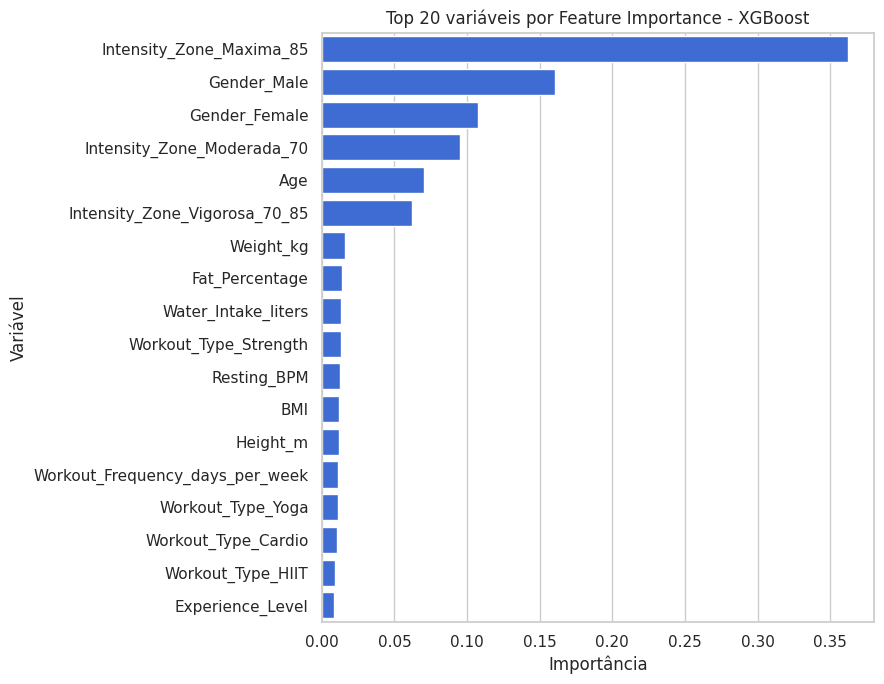

Interpretação:
Se variáveis associadas a Intensity_Zone e Experience_Level aparecem entre as mais importantes, isso sugere que intensidade e experiência contribuem para prever o gasto calórico por hora.


In [ ]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
importance_df = importance.rename("importance").reset_index().rename(columns={"index": "feature"})

display(importance_df.head(20))

plt.figure(figsize=(9, 7))
sns.barplot(data=importance_df.head(20), x="importance", y="feature", color="#2563eb")
plt.title("Top 20 variáveis por Feature Importance - XGBoost")
plt.xlabel("Importância")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()

print("Interpretação:")
print(
    "Se variáveis associadas a Intensity_Zone e Experience_Level aparecem entre as mais importantes, "
    "isso sugere que intensidade e experiência contribuem para prever o gasto calórico por hora."
)


### Tree SHAP

Os valores SHAP mostram como cada variável desloca a previsão do modelo para cada observação do teste final. As dummies de Intensity_Zone e Experience_Level são agrupadas para representar os construtos, evitando que uma interpretação dependa de uma única categoria codificada. SHAP explica o comportamento do modelo; não identifica mecanismos fisiológicos nem causalidade.


,mean_abs_SHAP
Age,35.957
Intensity_Zone_Maxima_85,35.301
Gender_Female,20.567
Intensity_Zone_Moderada_70,14.923
Gender_Male,5.871
Weight_kg,5.064
Fat_Percentage,4.279
Resting_BPM,4.054
Water_Intake_liters,2.959
Height_m,2.647


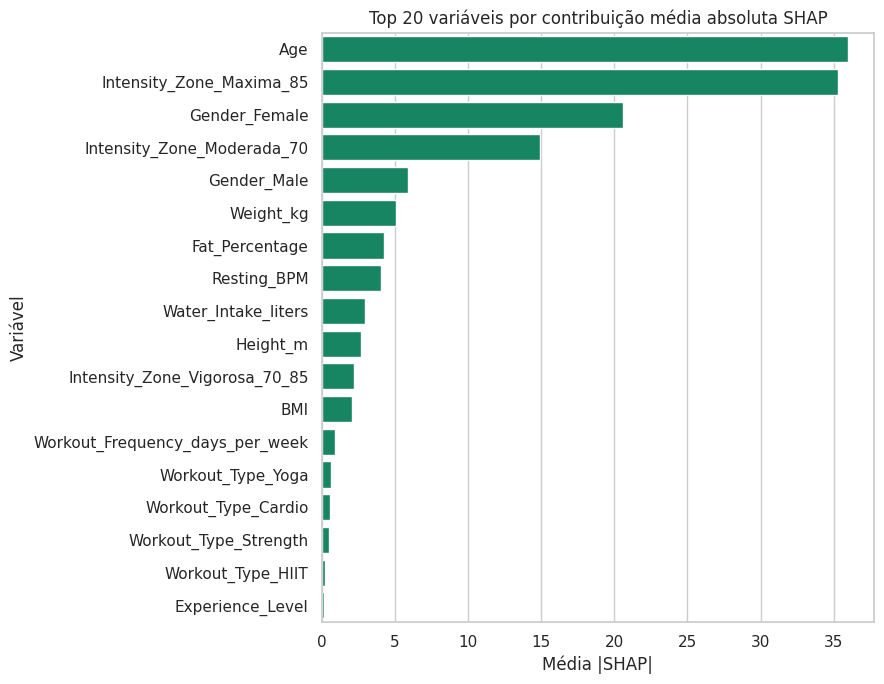

Contribuição SHAP agrupada para os construtos centrais de H1:


,mean_abs_grouped_SHAP
Intensity_Zone,52.401
Experience_Level,0.168


Interpretação:
O SHAP agrupado resume a contribuição das variáveis codificadas relacionadas à intensidade e à experiência. Quanto maior a média absoluta, maior a influência desse construto nas previsões do XGBoost.


In [ ]:
dtest = xgb.DMatrix(X_test, feature_names=list(X_test.columns))
shap_values = model.get_booster().predict(dtest, pred_contribs=True)

shap_df = pd.DataFrame(shap_values[:, :-1], columns=X_test.columns, index=X_test.index)
shap_base_value = shap_values[:, -1]
shap_abs = shap_df.abs().mean().sort_values(ascending=False)

display(shap_abs.rename("mean_abs_SHAP").head(20).to_frame())

plt.figure(figsize=(9, 7))
sns.barplot(x=shap_abs.head(20).values, y=shap_abs.head(20).index, color="#059669")
plt.title("Top 20 variáveis por contribuição média absoluta SHAP")
plt.xlabel("Média |SHAP|")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()

grouped_shap = pd.Series({
    "Intensity_Zone": shap_df[[c for c in shap_df.columns if c.startswith("Intensity_Zone_")]].abs().sum(axis=1).mean()
        if any(c.startswith("Intensity_Zone_") for c in shap_df.columns) else np.nan,
    "Experience_Level": shap_df[[c for c in shap_df.columns if c.startswith("Experience_Level")]].abs().sum(axis=1).mean()
        if any(c.startswith("Experience_Level") for c in shap_df.columns) else np.nan,
}).rename("mean_abs_grouped_SHAP")

print("Contribuição SHAP agrupada para os construtos centrais de H1:")
display(grouped_shap.to_frame())

print("Interpretação:")
print(
    "O SHAP agrupado resume a contribuição das variáveis codificadas relacionadas à intensidade e à experiência. "
    "Quanto maior a média absoluta, maior a influência desse construto nas previsões do XGBoost."
)


In [ ]:
max_cols = [c for c in shap_df.columns if "Intensity_Zone_Maxima" in c]
if max_cols:
    max_col = max_cols[0]
    max_mask = X_test[max_col] == 1
    if max_mask.any():
        max_shap_mean = shap_df.loc[max_mask, max_col].mean()
        direction = "aumentou" if max_shap_mean > 0 else "reduziu"
        print(
            f"Entre as observações classificadas como intensidade máxima, essa categoria {direction} "
            f"a previsão em {abs(max_shap_mean):.2f} calorias por hora, em média."
        )

cv_r2 = cv_summary.loc[cv_summary["Métrica"] == "R²", "Média (CV de 5 dobras)"].iloc[0]
zone_shap = grouped_shap.get("Intensity_Zone", np.nan)
experience_shap = grouped_shap.get("Experience_Level", np.nan)
print("\nSíntese de H1:")
print(
    f"O modelo obteve R² médio de {cv_r2:.3f} na validação cruzada e R² de {r2:.3f} no teste final. "
    f"O SHAP agrupado foi {zone_shap:.2f} para intensidade e {experience_shap:.2f} para experiência. "
    "Esses resultados sustentam utilidade preditiva na base analisada, não uma relação causal."
)


Entre as observações classificadas como intensidade máxima, essa categoria aumentou a previsão em 56.47 calorias por hora, em média.

Síntese de H1:
O modelo obteve R² médio de 0.678 na validação cruzada e R² de 0.695 no teste final. O SHAP agrupado foi 52.40 para intensidade e 0.17 para experiência. Esses resultados sustentam utilidade preditiva na base analisada, não uma relação causal.


## 13. H2: duração da sessão e calorias totais

H2 pergunta sobre uma associação linear entre duração e gasto total; por isso, Pearson é o resultado principal. Spearman é apresentado como análise de sensibilidade para uma associação baseada em postos. Os testes de normalidade são diagnósticos e não a única regra para escolher uma correlação.


In [ ]:
h2_data = df[["Session_Duration", "Calories_Burned"]].dropna()

def normality_pvalue(series):
    if len(series) < 3:
        return np.nan
    return stats.shapiro(series).pvalue if len(series) <= 5000 else stats.normaltest(series).pvalue

linear_fit = stats.linregress(h2_data["Session_Duration"], h2_data["Calories_Burned"])
residuals = h2_data["Calories_Burned"] - (
    linear_fit.intercept + linear_fit.slope * h2_data["Session_Duration"]
)
residual_normality_p = normality_pvalue(residuals)
pearson_r, pearson_p = stats.pearsonr(h2_data["Session_Duration"], h2_data["Calories_Burned"])
spearman_r, spearman_p = stats.spearmanr(h2_data["Session_Duration"], h2_data["Calories_Burned"])

h2_results = pd.DataFrame({
    "Resultado": ["Normalidade dos resíduos lineares", "Pearson (principal)", "Spearman (sensibilidade)"],
    "Coeficiente": [np.nan, pearson_r, spearman_r],
    "p-valor": [residual_normality_p, pearson_p, spearman_p],
})
display(h2_results)

print(
    f"H2: Pearson r = {pearson_r:.3f}, p = {pearson_p:.4g}; "
    f"Spearman ρ = {spearman_r:.3f}, p = {spearman_p:.4g}."
)
print(
    "A semelhança entre os coeficientes reforça a leitura de associação positiva; "
    "ela não separa o efeito da duração de outras características não controladas."
)


,Resultado,Coeficiente,p-valor
0,Normalidade dos resíduos lineares,NaN,0.004
1,Pearson (principal),0.908,0.000
2,Spearman (sensibilidade),0.903,0.000


H2: Pearson r = 0.908, p = 0; Spearman ρ = 0.903, p = 0.
A semelhança entre os coeficientes reforça a leitura de associação positiva; ela não separa o efeito da duração de outras características não controladas.


## 14. H3: gasto calórico por hora e experiência

Comparar Calories_Burned confundiria experiência com duração, pois o gasto total tende a crescer mecanicamente quando a sessão é mais longa. Assim, H3 usa Calories_per_Hour. Primeiro são verificados normalidade por grupo e homogeneidade de variâncias; aplica-se ANOVA quando ambos os pressupostos são razoáveis e Kruskal–Wallis caso contrário. Se houver diferença global, comparações por pares com correção de Holm indicam onde ela aparece.


,count,mean,median,std
Experience_Level,,,,
1,376,718.788,719.688,88.766
2,406,722.415,715.242,84.104
3,191,719.399,715.084,89.559


,Experience_Level,normality_p,normal
0,1,0.000,False
1,2,0.001,False
2,3,0.115,True


,Critério/Teste,Estatística,p-valor
0,Levene,0.494,0.610
1,Kruskal-Wallis,0.608,0.738


Tamanho de efeito (epsilon²): 0.000
Sem pós-teste: a comparação global não foi estatisticamente significativa.


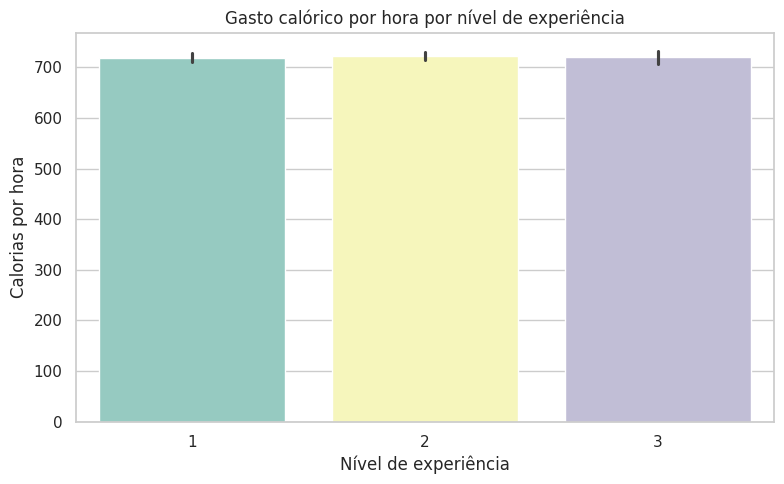

H3: Kruskal-Wallis, H = 0.608, p = 0.7378; não há evidência estatística de diferença em Calories_per_Hour entre os níveis de experiência.


In [ ]:
h3_data = df[["Experience_Level", "Calories_per_Hour"]].dropna().copy()
grouped = list(h3_data.groupby("Experience_Level", observed=True))
group_labels = [label for label, group in grouped if len(group) >= 2]
groups = [group["Calories_per_Hour"].to_numpy() for _, group in grouped if len(group) >= 2]

if len(groups) < 2:
    raise ValueError("H3 requer pelo menos dois níveis de experiência com duas ou mais observações.")

group_summary = h3_data.groupby("Experience_Level", observed=True)["Calories_per_Hour"].agg(["count", "mean", "median", "std"])
display(group_summary)

normality_df = pd.DataFrame([
    {
        "Experience_Level": label,
        "normality_p": normality_pvalue(pd.Series(values)),
        "normal": normality_pvalue(pd.Series(values)) > 0.05,
    }
    for label, values in zip(group_labels, groups)
])
display(normality_df)

levene_stat, levene_p = stats.levene(*groups, center="median")
all_normal = bool(normality_df["normal"].all())
homoscedastic = bool(levene_p > 0.05)

if all_normal and homoscedastic:
    selected_h3 = "ANOVA"
    stat_label = "F"
    stat_value, p_value = stats.f_oneway(*groups)
    grand_mean = h3_data["Calories_per_Hour"].mean()
    ss_between = sum(len(values) * (values.mean() - grand_mean) ** 2 for values in groups)
    ss_total = ((h3_data["Calories_per_Hour"] - grand_mean) ** 2).sum()
    effect_size = ss_between / ss_total
    effect_label = "eta²"
else:
    selected_h3 = "Kruskal-Wallis"
    stat_label = "H"
    stat_value, p_value = stats.kruskal(*groups)
    effect_size = max(0, (stat_value - len(groups) + 1) / (len(h3_data) - len(groups)))
    effect_label = "epsilon²"

h3_results = pd.DataFrame({
    "Critério/Teste": ["Levene", selected_h3],
    "Estatística": [levene_stat, stat_value],
    "p-valor": [levene_p, p_value],
})
display(h3_results)
print(f"Tamanho de efeito ({effect_label}): {effect_size:.3f}")

def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted_sorted = np.maximum.accumulate((len(p_values) - np.arange(len(p_values))) * p_values[order])
    adjusted = np.empty_like(p_values)
    adjusted[order] = np.minimum(adjusted_sorted, 1.0)
    return adjusted

if p_value < 0.05:
    posthoc_rows = []
    for (label_a, values_a), (label_b, values_b) in itertools.combinations(zip(group_labels, groups), 2):
        if selected_h3 == "ANOVA":
            pair_stat, pair_p = stats.ttest_ind(values_a, values_b, equal_var=True)
            pair_test = "t independente"
        else:
            pair_stat, pair_p = stats.mannwhitneyu(values_a, values_b, alternative="two-sided")
            pair_test = "Mann-Whitney"
        posthoc_rows.append({
            "comparação": f"{label_a} vs {label_b}",
            "teste": pair_test,
            "estatística": pair_stat,
            "p_bruto": pair_p,
        })
    posthoc = pd.DataFrame(posthoc_rows)
    posthoc["p_Holm"] = holm_adjust(posthoc["p_bruto"])
    posthoc["significativo_5%"] = posthoc["p_Holm"] < 0.05
    display(posthoc)
else:
    print("Sem pós-teste: a comparação global não foi estatisticamente significativa.")

plt.figure(figsize=(8, 5))
sns.barplot(data=h3_data, x="Experience_Level", y="Calories_per_Hour", palette="Set3", errorbar=("ci", 95))
plt.title("Gasto calórico por hora por nível de experiência")
plt.xlabel("Nível de experiência")
plt.ylabel("Calorias por hora")
plt.tight_layout()
plt.show()

conclusion = "há diferença estatisticamente significativa" if p_value < 0.05 else "não há evidência estatística de diferença"
print(
    f"H3: {selected_h3}, {stat_label} = {stat_value:.3f}, p = {p_value:.4g}; {conclusion} "
    f"em Calories_per_Hour entre os níveis de experiência."
)


## 15. Discussão

O padrão mais robusto é avaliado quando os resultados convergem: médias por grupo, validação do modelo e análises SHAP para H1; Pearson e Spearman para H2; teste global, tamanho de efeito e pós-teste para H3. Divergências entre essas evidências devem ser tratadas como incerteza, não como confirmação automática da hipótese.

Há limites relevantes: dados observacionais, possível viés de seleção da base, variáveis não medidas (por exemplo, modalidade real do treino e condição física) e ausência de validação em outra amostra. As conclusões, portanto, são associativas e específicas ao conjunto disponível.


## 16. Conclusão

O notebook separa três perguntas distintas: previsão do gasto por hora (H1), associação entre duração e gasto total (H2) e comparação do gasto por hora entre níveis de experiência (H3). A validação cruzada e o teste final tornam H1 menos dependente de uma única divisão; H3 usa uma taxa para não confundir duração com gasto. Os resultados devem ser interpretados como evidência descritiva e preditiva da base analisada, não como prova de causalidade.
